In [43]:
import numpy as np 
import pandas as pd 
import os 
import cv2
import matplotlib.pyplot as plt
import warnings
import seaborn as sns
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Lambda, Dropout, Input, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.applications.vgg19 import VGG19, preprocess_input
from tensorflow.keras.preprocessing import image, image_dataset_from_directory
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing import image
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow import keras
import tensorflow as tf

In [30]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  2


In [31]:
data_dir = "C:/Users/Ahmet's Monster/Desktop/AugmentedAlzheimer/AugmentedAlzheimerDataset"

img_size = (224, 224)
batch_size = 32

train_data = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)

test_data = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)

classes_name = train_data.class_names

classes_name

Found 33984 files belonging to 4 classes.
Using 27188 files for training.
Found 33984 files belonging to 4 classes.
Using 6796 files for validation.


['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']

In [33]:
train_data = train_data.map(lambda x, y: (preprocess_input(x), y))
test_data = test_data.map(lambda x, y: (preprocess_input(x), y))

In [39]:
model = Sequential()

base_model = VGG19(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

model.add(base_model)

model.add(GlobalAveragePooling2D())
model.add(Dense(256, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))

model.add(Dense(len(classes_name), activation='softmax'))

model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

model.fit(train_data, validation_data=test_data, epochs=3)

base_model.trainable = True
for layer in base_model.layers[:-4]: 
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=0.00001), loss='categorical_crossentropy', metrics=['accuracy'])

earlyStop = EarlyStopping(
    monitor='val_accuracy', 
    patience=4, 
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_data, 
    validation_data=test_data, 
    epochs=15, 
    callbacks=[earlyStop]
)


Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg19 (Functional)          (None, 7, 7, 512)         20024384  
                                                                 
 global_average_pooling2d_3   (None, 512)              0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dense_15 (Dense)            (None, 256)               131328    
                                                                 
 batch_normalization_3 (Batc  (None, 256)              1024      
 hNormalization)                                                 
                                                                 
 dropout_8 (Dropout)         (None, 256)               0         
                                                                 
 dense_16 (Dense)            (None, 4)                

1/1 [==============================] - 0s 117ms/step


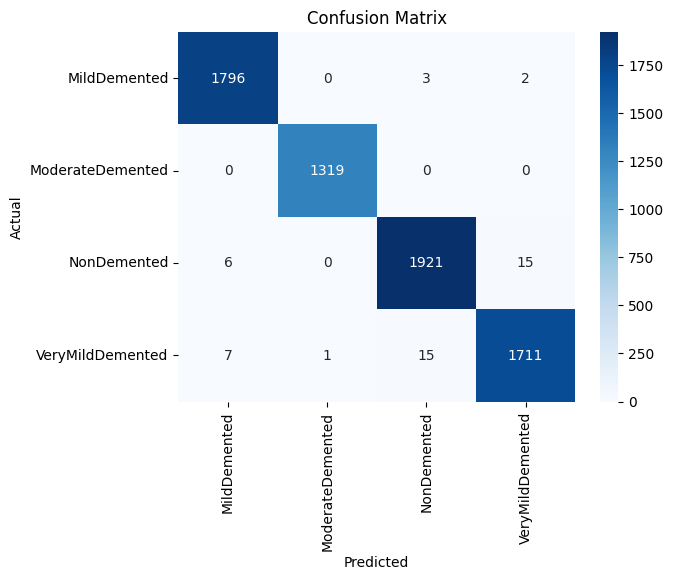

In [40]:
real_values = []
predicted_values = []

for images, labels in test_data:
    predictions = model.predict(images)
    predicted_classes = np.argmax(predictions, axis=1)
    real_classes = np.argmax(labels.numpy(), axis=1)

    real_values.extend(real_classes)
    predicted_values.extend(predicted_classes)

real_values = np.array(real_values)
predicted_values = np.array(predicted_values)

cm = confusion_matrix(real_values, predicted_values)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes_name, yticklabels=classes_name)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [42]:
print(classification_report(real_values, predicted_values, target_names=classes_name))

                  precision    recall  f1-score   support

    MildDemented       0.99      1.00      1.00      1801
ModerateDemented       1.00      1.00      1.00      1319
     NonDemented       0.99      0.99      0.99      1942
VeryMildDemented       0.99      0.99      0.99      1734

        accuracy                           0.99      6796
       macro avg       0.99      0.99      0.99      6796
    weighted avg       0.99      0.99      0.99      6796



In [56]:
img = image.load_img("C:/Users/Ahmet's Monster/Desktop/AugmentedAlzheimer/brain.jpg", target_size=(224, 224))

img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

predict = model.predict(img_array)
predicted_class = classes_name[np.argmax(predict)]

predicted_class

1/1 [==============================] - 0s 21ms/step


'MildDemented'